# Week 10 Assignment 
## Data 620
### Jane Song

## Introduction 

For this assignment, I will be using the UCI Machine Learning Repository to predict the class of documents is spam. This involves supervised classification and requires splitting the dataset into 2: 
- Training data: data with known labels
- Test data: data with labels we hide from the model and then compare its predictions against the true labels. This simulates how the model would behave 

After splitting the data, I will implement several different models to evaluate which performs best for this task. 

## Load the data 

In [56]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)



In [57]:
# Load dataset from UCI repo
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
spambase = fetch_ucirepo(id=94) 
  
# data (as pandas dataframes) 
X = spambase.data.features 
y = spambase.data.targets 
  
# metadata 
print(spambase.metadata) 
  
# variable information 
print(spambase.variables)

{'uci_id': 94, 'name': 'Spambase', 'repository_url': 'https://archive.ics.uci.edu/dataset/94/spambase', 'data_url': 'https://archive.ics.uci.edu/static/public/94/data.csv', 'abstract': 'Classifying Email as Spam or Non-Spam', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 4601, 'num_features': 57, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1999, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C53G6X', 'creators': ['Mark Hopkins', 'Erik Reeber', 'George Forman', 'Jaap Suermondt'], 'intro_paper': None, 'additional_info': {'summary': 'The "spam" concept is diverse: advertisements for products/web sites, make money fast schemes, chain letters, pornography...\n\nThe classification task for this dataset is to determine whether a given email is spam or not.\n\t\nOur collecti

In [58]:
# Check shape and variables of dataset
print(X.shape)
print(y.shape)

# Check details of dataset
print(spambase.metadata["additional_info"]["summary"])
spambase.variables.head(10)

(4601, 57)
(4601, 1)
The "spam" concept is diverse: advertisements for products/web sites, make money fast schemes, chain letters, pornography...

The classification task for this dataset is to determine whether a given email is spam or not.
	
Our collection of spam e-mails came from our postmaster and individuals who had filed spam.  Our collection of non-spam e-mails came from filed work and personal e-mails, and hence the word 'george' and the area code '650' are indicators of non-spam.  These are useful when constructing a personalized spam filter.  One would either have to blind such non-spam indicators or get a very wide collection of non-spam to generate a general purpose spam filter.

For background on spam: Cranor, Lorrie F., LaMacchia, Brian A.  Spam!, Communications of the ACM, 41(8):74-83, 1998.

Typical performance is around ~7% misclassification error. False positives (marking good mail as spam) are very undesirable.If we insist on zero false positives in the training/tes

,name,role,type,demographic,description,units,missing_values
0,word_freq_make,Feature,Continuous,None,None,None,no
1,word_freq_address,Feature,Continuous,None,None,None,no
2,word_freq_all,Feature,Continuous,None,None,None,no
3,word_freq_3d,Feature,Continuous,None,None,None,no
4,word_freq_our,Feature,Continuous,None,None,None,no
5,word_freq_over,Feature,Continuous,None,None,None,no
6,word_freq_remove,Feature,Continuous,None,None,None,no
7,word_freq_internet,Feature,Continuous,None,None,None,no
8,word_freq_order,Feature,Continuous,None,None,None,no
9,word_freq_mail,Feature,Continuous,None,None,None,no


The df `X` holds the 57 feature columns and `y` holds the `Class` label (a one-column DataFrame). For exploration it is convenient to have them together in one dataFrame so I merge them.

In [59]:
# merge targets and features datasets

df = pd.concat([X, y], axis=1)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (4601, 58)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,Class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


## Checking data

It is important to check a few things before training data:

- Missing values: Models in scikit-learn generally cannot handle missing data
- Class balance: Knowing the balance can help determien whether accuracy alone is a trustworthy metric

Missing values: 0
Class
ham     2788
spam    1813
Name: count, dtype: int64

Class
ham     0.606
spam    0.394
Name: count, dtype: float64


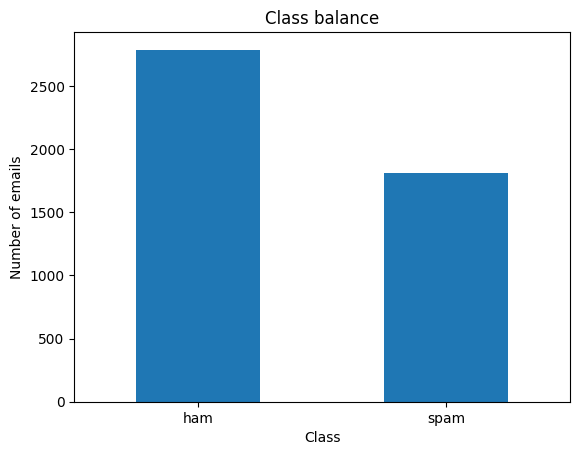

In [60]:
print("Missing values:", df.isna().sum().sum())
balance = df["Class"].value_counts().rename({0: "ham", 1: "spam"})
print(balance)
print()
print((balance / len(df)).round(3))
balance.plot(kind="bar", title="Class balance", rot=0)
plt.ylabel("Number of emails")
plt.show()

There are no missing values, so no cleaning is needed. The classes are a bit imbalanced (roughly 60% ham and 40% spam). This is not extreme, so accuracy is still meaningful, but a model that always predicts "ham" would already score about 60%. 60% accuracy is the baseline for this model for it to likely be effective. Because the imbalance exists, I will also report precision, recall and F1, which describe performance on the spam class specifically. These metrics are defined as:
- Precision: The proportion of positive predictions that were actually correct. This measures how often the model is correct when it predicts a positive result
- Recall (Sensitivity): The proportion of actual positive cases that the model correctly identifies. This measures how well the model finds all positive cases
- F1 Score: Balances the precision and recall metrics and is useful when evaluating both false positives and false negatives

## Split into training and test sets 

The data will be split into 80% training and 20% test. The model is fit only on the training dataset. The test dataset is never used during training, so scores on it estimate how the model would do on brand new email.

In [61]:
# Split dataset 0.8/0.2 
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=12, stratify=y)

print("Training emails:", len(X_train), "| Test emails:", len(X_test))

Training emails: 3680 | Test emails: 921


## Train data set using different models 

I will try 3 different models:

Naive Bayes: Calculates the probability that an observation belongs to a particular class based on its features. It assumes that the features are independent of one another

Logistic regression: Estimates the probability that an observation belongs to a particular class based on one or more predictor variables. It uses a logistic (sigmoid) function to convert the model output into a probability between 0 and 1

Random Forest: An ensemble learning algorithm that combines multiple decision trees to make a prediction. Each tree is trained using a random sample of the data and a random subset of features. For classification, the final prediction is typically determined by majority voting across the trees

In [62]:
# Train data using different models 
 
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=123),}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)           
    predictions[name] = model.predict(X_test)   


## Predict the test set

For a spam filter, there are two kinds of mistakes:

- False positive: a legitimate email is flagged as spam. This is the worse error since the user might miss an important message (bills, interview requests, etc)
- False negative: a spam email ends up in the main inbox. This less harmful than a false positive in most cases

Because false positives are especially bad here, precision should be prioritized in this case.

In [63]:
# Results for classification metrics 
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1
Model,,,,
Multinomial Naive Bayes,0.8100,0.7640,0.7493,0.7566
Logistic Regression,0.9294,0.9139,0.9063,0.9101
Random Forest,0.9533,0.9396,0.9421,0.9409


All three models beat the 60% baseline of always predicting ham and performed relatively well. The random forest performed best (accuracy 95.3%) and exceeded the roughly 93% accuracy the dataset authors report as typical in their notes. Logistic regression (92.9%) was close to that benchmark, while Naive Bayes (81%) was the weakest.

Because false positives are the costlier error for a spam filter, precision was a priority metric. The random forest also had the highest precision (~94%), so it is the model I would deploy. 


## Confusion matrix

A confusion matrix is helpful in showing where each model goes wrong. Rows are the true class and columns are the predicted class. The top-right cell is false positives (ham called spam) and the bottom-left is false negatives (spam called ham).

We saw previously that the random forest performed best (accuracy 95%, precision 94%, recall 95%). Because false positives are the costlier error for a spam filter, the confusion matrices are especially informative to understand the results of this error.

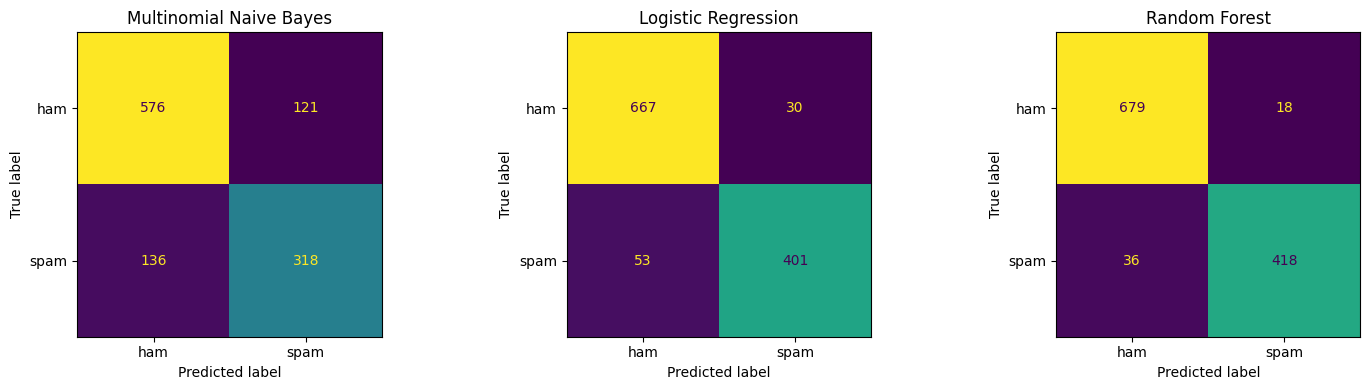

In [ ]:
# Create confusion matrix 

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["ham", "spam"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Random forest wrongly flagged 18 of 697 legitimate emails (about 2.6%), compared with 30 for logistic regression and 121 for Naive Bayes. It also missed the fewest spam emails (36 of 454). The same model therefore leads on both error types so there is no trade-off in choosing it. Naive Bayes performed poorly on both types of errors. However, the 18 false positives would mean legitimate mail lost in a real inbox so further tuning may be needed before usage.

## Cross-validation

A single train/test split can be lucky or unlucky depending on which emails land in the test set. 5-fold cross-validation repeats the process five times with the data divided into five parts. Each part takes a turn as the test set while the other four train the model. The average score is more reliable, and the standard deviation shows how stable the model is. This can help confirm our initial results. 

In [64]:

cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
    cv_rows.append({"Model": name, "Mean accuracy": scores.mean(), "Std dev": scores.std()})
pd.DataFrame(cv_rows).set_index("Model").round(4)

,Mean accuracy,Std dev
Model,,
Multinomial Naive Bayes,0.7818,0.0443
Logistic Regression,0.9120,0.0357
Random Forest,0.9289,0.0543


Cross-validated accuracy ranked the models the same way as the single split: random forest (93%), logistic regression (91%), Naive Bayes (78%). The standard deviations (3.6 to 5.4 points) are large, and the gap between the forest and logistic regression is smaller than that variation, so I cannot conclude from this alone that the forest is clearly better. The consistently large gap to Naive Bayes, however, is clear under every split.

## Inspect which features drive the predictions

A classifier is more convincing if we can explain why it works. The random forest reports feature importance which is how much each feature reduced uncertainty across all its trees. Higher means more useful for separating spam from ham.

char_freq_$                   0.1194
char_freq_!                   0.1142
word_freq_remove              0.0804
word_freq_free                0.0722
capital_run_length_average    0.0649
word_freq_your                0.0515
capital_run_length_longest    0.0481
word_freq_hp                  0.0406
capital_run_length_total      0.0373
word_freq_money               0.0367
dtype: float64


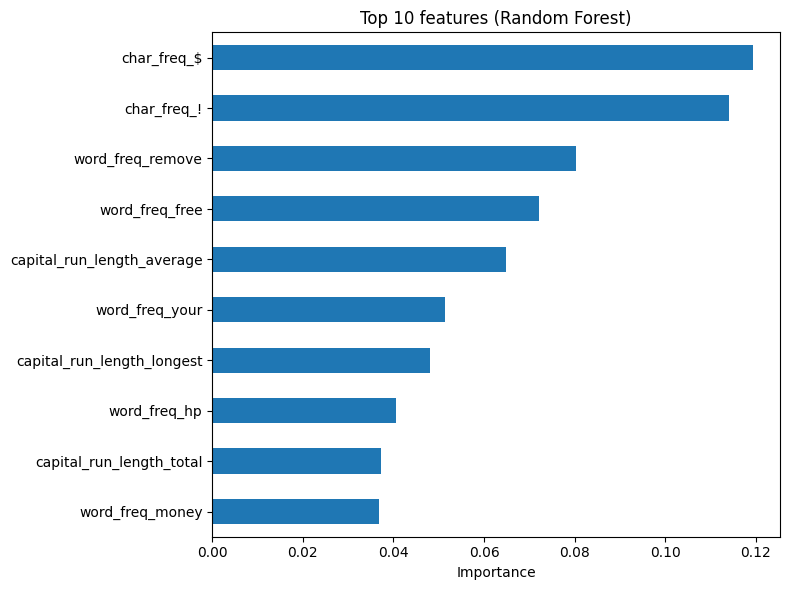

In [65]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(10).round(4))

importances.head(10)[::-1].plot(kind="barh", figsize=(8, 6))
plt.title("Top 10 features (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

The random forest relies most heavily on the frequency of the dollar sign (char_freq_$, 0.123) and the exclamation mark (char_freq_!, 0.113). Together these two characters account for about 24% of the model’s total importance, more than any single word. Next come the words remove (0.072) and free (0.067), followed by the capital-letter features, capital_run_length_average (0.063), capital_run_length_longest (0.053) and capital_run_length_total (0.041), and the words your (0.052) and money (0.041).

The ten features shown add up to about 67% of the total importance, so most of the model’s decisions rest on a small group of features, while the other 47 share the remaining third.

## Conclusion 

The goal of this project was to classify emails as spam or ham using already-labeled examples. I trained three models on the UCI Spambase dataset and evaluated them on held-out emails. All three performed relatively well but they still differed in quality. The random forest performed best, with 95% accuracy, 94% precision and 924% recall on the test set. Logistic regression was close behind (93% accuracy), while Multinomial Naive Bayes was clearly the weakest (81% accuracy).

The more costly mistake for a spam filter is blocking legitimate mail so precision and false positives were considered most important. The random forest wrongly flagged 18 of 697 legitimate emails (about 2.6%), compared with 30 for logistic regression and 121 for Naive Bayes. It also missed the fewest spam emails (36 of 454), so it led on both kinds of error and I would choose it over the other two.

Five-fold cross-validation was also utilized to help confirm results. The ranking was the same but the random forest’s accuracy fell to 93%, which is roughly the ~93% the dataset authors describe as typical. The standard deviations were large (3.6 to 5.4 points), and the gap between the forest and logistic regression was smaller than that variation, so I cannot say the forest is clearly better than logistic regression from this evidence alone. The large gap to Naive Bayes is consistent in both models. 

The most important features for the random forest were the frequency of $ and !, followed by remove, free, and the capital-letter run features. 

While I would recommend using the random forest model, it still had false positives which can mean important emails falling through the cracks. I think it would be important to further tune the model. In addition, I noticed that this dataset is from 1999, over 27 years ago! Real life utilization will likely not be as accurate since the way messages are written have changed significantly over time. 
